# Classificação de batimentos cardíacos: avaliação honesta por paciente

Projeto final da Trilha de Trainees Insper AI (Tom e Renata).

**Pergunta:** quanto do desempenho "bonito" (~98-99%) de classificadores de arritmia some quando o teste usa pacientes que o modelo nunca viu, principalmente na classe S? E o que ajuda a recuperar parte dessa queda?

**Como ler:** cada seção tem o título numa célula separada. No VS Code dá para recolher a seção e ver só os títulos. O plano completo e o log de decisões estão no `CLAUDE.md`.

**Como rodar:** no Colab, direto. No computador, criar o ambiente com `python -m venv .venv` e `.venv\Scripts\python -m pip install -r requirements.txt`, e escolher o kernel `.venv` no VS Code. Rodar tudo leva ~2 min (só CPU).

## Glossário

**Classes de batimento** (padrão AAMI). Contagens = as 44 gravações do nosso dataset.

| Classe | Nome | O que é, em termos simples | Símbolos MIT-BIH | Batimentos |
|---|---|---|---|---|
| **N** | Normal | Batimento que segue o caminho elétrico normal do coração. Inclui variações como bloqueio de ramo (L, R) | N, L, R, e, j | 90.042 |
| **S** | Supraventricular ectópico | Batimento que nasce **antes da hora**, num ponto acima dos ventrículos (átrios ou junção). O formato é parecido com o do N; o que muda é o momento | A, a, J, S | 2.779 |
| **V** | Ventricular ectópico | Batimento que nasce antes da hora **nos próprios ventrículos**. A onda fica larga e com formato estranho | V, E | 7.007 |
| **F** | Fusão | Um batimento normal e um ventricular acontecem quase juntos e as ondas se misturam | F | 802 |
| **Q** | Desconhecido | Batimentos não classificáveis (no MIT-BIH completo, também os de marcapasso). Quase some aqui e sai da avaliação | /, f, Q | 15 |

**Termos usados no notebook**

| Termo | Significado |
|---|---|
| **Pico R** | O pico alto e fino de cada batimento no ECG. Os cardiologistas marcaram a posição de cada um. |
| **Um dado = um batimento** | Cada pico R anotado vira um exemplo: uma janela de 1 s do sinal ao redor dele, com a classe que o cardiologista deu. O modelo nunca vê a gravação inteira. |
| **Intervalo RR** | Tempo entre dois picos R seguidos, ou seja, entre dois batimentos. RR de 0,8 s = 75 batimentos por minuto (60 ÷ 0,8). |
| **Derivação MLII** | Um dos "ângulos" de onde o ECG mede o coração. Cada gravação tem dois; usamos a MLII, a mais comum nos artigos. |
| **DS1 / DS2** | Grupos de 22 pacientes cada (de Chazal et al., 2004). DS1 = treino, DS2 = teste. Nenhum paciente aparece nos dois. |
| **Split aleatório × por paciente** | Aleatório: sorteia batimentos, então o mesmo paciente cai no treino e no teste. Por paciente: o teste só tem pessoas que o modelo nunca viu. |

## 0. Status do projeto

Atualizar sempre que uma etapa mudar.

| Seção | Status |
|---|---|
| 1. Configuração | Pronto, rodado |
| 2. Teste de leitura (gravação 100) | Pronto, rodado (05/11) |
| 3. Montagem do dataset | Pronto, rodado (05/11). Escolhas provisórias, a confirmar com o Tom |
| 4. EDA | Pronto, rodado (05/11) |
| 5. Divisão dos dados | Pronto, rodado (05/11). Escolhas provisórias, a confirmar com o Tom |
| 6. Experimentos E0-E5 | E0, E1, E2 rodados (05/11, uma seed). E3-E5 a fazer |
| 7. Análise de erros | A fazer |
| 8. Conclusões | A fazer |

## 1. Configuração

Instala o `wfdb` se precisar (biblioteca do PhysioNet para ler os arquivos de ECG), importa as bibliotecas e fixa as seeds para que os resultados se repitam a cada execução. A seed do TensorFlow é fixada na seção de experimentos, quando ele for importado.

In [1]:
# Instala o wfdb só se ele não existir (ex.: no Colab). Instalar sem precisar
# pode atualizar numpy/pandas e quebrar outros pacotes do ambiente local.
try:
    import wfdb
except ImportError:
    %pip install -q wfdb

In [2]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DADOS_DIR = "mitdb"  # pasta onde as gravações do MIT-BIH são salvas

## 2. Teste de leitura dos dados (gravação 100)

Antes de montar o dataset, confirmamos que conseguimos baixar uma gravação, ler o sinal e ler as anotações dos cardiologistas (posição e tipo de cada batimento).

- Cada gravação tem um arquivo de sinal (`rdrecord`) e um de anotações `.atr` (`rdann`).
- Escolhemos o canal pelo **nome** (`MLII`), e não pela posição, porque a ordem das derivações pode mudar entre gravações.
- Nem toda anotação é um batimento: alguns símbolos (como `+`) marcam mudança de ritmo. Na montagem do dataset vamos manter só os símbolos de batimento.

In [3]:
wfdb.dl_database("mitdb", dl_dir=DADOS_DIR, records=["100"])

registro = wfdb.rdrecord(f"{DADOS_DIR}/100")
anotacao = wfdb.rdann(f"{DADOS_DIR}/100", "atr")

print("Frequência (Hz):", registro.fs)
print("Derivações:", registro.sig_name)
print("Formato do sinal (amostras, canais):", registro.p_signal.shape)
print("Primeiras posições anotadas:", anotacao.sample[:10])
print("Primeiros símbolos:", anotacao.symbol[:10])

Generating record list for: 100
Generating list of all files for: 100


Finished downloading files
Frequência (Hz): 360
Derivações: ['MLII', 'V5']
Formato do sinal (amostras, canais): (650000, 2)
Primeiras posições anotadas: [  18   77  370  662  946 1231 1515 1809 2044 2402]
Primeiros símbolos: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


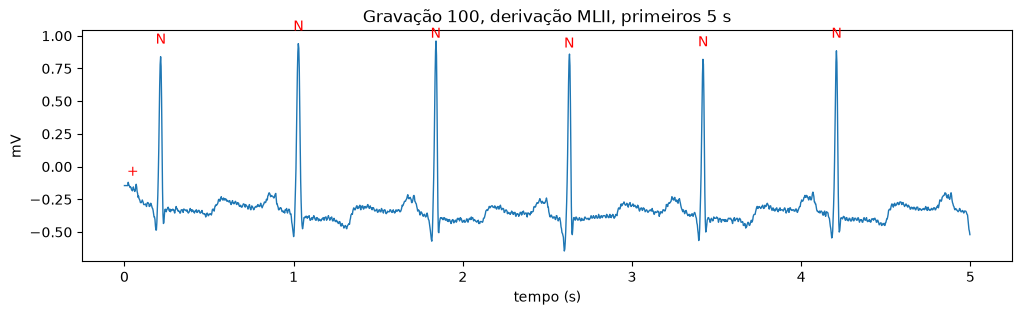

In [4]:
# Plota os primeiros 5 segundos da MLII com o símbolo de cada anotação
fs = registro.fs
canal = registro.sig_name.index("MLII")
n = 5 * fs
t = np.arange(n) / fs
sinal = registro.p_signal[:n, canal]

dentro = anotacao.sample < n
posicoes = anotacao.sample[dentro]
simbolos = np.array(anotacao.symbol)[dentro]

plt.figure(figsize=(12, 3))
plt.plot(t, sinal, lw=1)
for pos, simbolo in zip(posicoes, simbolos):
    plt.text(pos / fs, sinal[pos] + 0.1, simbolo, ha="center", color="red")
plt.xlabel("tempo (s)")
plt.ylabel("mV")
plt.title("Gravação 100, derivação MLII, primeiros 5 s")
plt.show()

In [5]:
# Quantas anotações de cada símbolo existem na gravação inteira
Counter(anotacao.symbol)

Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})

**Resultado do teste (05/11):** a leitura funciona. O sinal tem 360 Hz e duas derivações (MLII e V5), e cada anotação cai em cima do pico R, então dá para usar `anotacao.sample` como centro da janela de cada batimento. A gravação 100 tem 2.239 batimentos N, 33 A (classe S) e 1 V; o `+` é marca de ritmo e será descartado.

## 3. Montagem do dataset

Montamos o dataset com **uma linha por batimento**, usando as 44 gravações sem marcapasso (as mesmas nos dois splits, para a comparação ser justa). Ele fica em duas variáveis:

- `df`: tabela com `paciente` (gravação), `split` (DS1/DS2), `classe` (N/S/V/F/Q), `simbolo` original, `posicao` do pico R, `rr_anterior` e `rr_posterior` (segundos até o batimento anterior e até o próximo).
- `X`: matriz com o sinal; a linha `i` de `X` é a janela do batimento da linha `i` de `df`.

**Escolhas (provisórias, a confirmar com o Tom):**
- **Derivação MLII**, escolhida pelo nome. Na gravação 114 ela é o 2º canal, não o 1º.
- **Janela larga: 0,5 s antes e 0,5 s depois do pico R** (180 + 180 amostras). Cobre a onda P (antes do pico) e a onda T (depois). O tamanho final usado no modelo é recortado desta janela, então dá para testar tamanhos sem remontar o dataset.
- **Sinal em mV, sem normalizar.** A normalização é decidida na seção 5 (se for global, com estatísticas só do treino).
- **Só os 15 símbolos de batimento da tabela AAMI.** As outras anotações (`+` ritmo, `~` qualidade, `!` onda de flutter, comentários) são descartadas.
- **RR calculado com todos os batimentos da gravação.** O primeiro e o último batimento de cada gravação saem, porque não têm os dois RR.

O significado de cada símbolo foi conferido na tabela de anotações da própria `wfdb` (`wfdb.io.annotation.ann_label_table`).

In [6]:
# Símbolo do MIT-BIH -> classe AAMI EC57
MAPA_AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q",
}

# Gravações com marcapasso, excluídas do split por paciente
MARCAPASSO = ["102", "104", "107", "217"]

# Split por paciente de de Chazal et al. (2004)
DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]  # treino
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]  # teste

assert len(DS1) == 22 and len(DS2) == 22 and not set(DS1) & set(DS2)

In [7]:
GRAVACOES = DS1 + DS2
ANTES, DEPOIS = 180, 180  # amostras de cada lado do pico R (0,5 s a 360 Hz)

# Baixa as 44 gravações (só o que ainda não estiver na pasta). O print do wfdb é longo, então fica escondido.
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    wfdb.dl_database("mitdb", dl_dir=DADOS_DIR, records=GRAVACOES, annotators=["atr"])

In [8]:
def extrair_batimentos(gravacao):
    """Recorta a janela de cada batimento de uma gravação e calcula os intervalos RR."""
    registro = wfdb.rdrecord(f"{DADOS_DIR}/{gravacao}", channel_names=["MLII"])
    sinal = registro.p_signal[:, 0]
    anotacao = wfdb.rdann(f"{DADOS_DIR}/{gravacao}", "atr")

    simbolos = np.array(anotacao.symbol)
    eh_batimento = np.isin(simbolos, list(MAPA_AAMI))
    posicoes, simbolos = anotacao.sample[eh_batimento], simbolos[eh_batimento]
    rr = np.diff(posicoes) / registro.fs  # rr[k] = segundos entre o batimento k e o k+1

    linhas, janelas = [], []
    for k in range(1, len(posicoes) - 1):  # pula o primeiro e o último (sem RR dos dois lados)
        pos = posicoes[k]
        if pos - ANTES < 0 or pos + DEPOIS > len(sinal):
            continue
        janelas.append(sinal[pos - ANTES : pos + DEPOIS])
        linhas.append({"paciente": gravacao, "classe": MAPA_AAMI[simbolos[k]], "simbolo": simbolos[k],
                       "posicao": pos, "rr_anterior": rr[k - 1], "rr_posterior": rr[k]})
    return linhas, janelas

In [9]:
todas_linhas, todas_janelas = [], []
for gravacao in GRAVACOES:
    linhas, janelas = extrair_batimentos(gravacao)
    todas_linhas += linhas
    todas_janelas += janelas

df = pd.DataFrame(todas_linhas)
df["split"] = np.where(df["paciente"].isin(DS1), "DS1", "DS2")
X = np.array(todas_janelas, dtype=np.float32)

print("Batimentos:", len(df), "| formato de X:", X.shape)
df.head()

Batimentos: 100645 | formato de X: (100645, 360)


,paciente,classe,simbolo,posicao,rr_anterior,rr_posterior,split
0,101,N,N,396,0.869444,0.875000,DS1
1,101,N,N,711,0.875000,0.891667,DS1
2,101,N,N,1032,0.891667,0.933333,DS1
3,101,N,N,1368,0.933333,0.955556,DS1
4,101,N,N,1712,0.955556,0.900000,DS1


## 4. Análise exploratória (EDA)

Três perguntas antes de treinar qualquer modelo:
1. Quantos batimentos há de cada classe, e os números batem com a literatura?
2. A classe S depende de poucos pacientes?
3. As classes têm formato de onda e ritmo diferentes?

In [10]:
# Cores fixas por classe, iguais em todos os gráficos do notebook
CLASSES = ["N", "S", "V", "F"]
CORES = {"N": "#2a78d6", "S": "#eb6834", "V": "#1baf7a", "F": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})

### 4.1 Contagem por classe

O dataset tem **100.645 batimentos**. As contagens de S, V, F e Q batem com a literatura (diferença de no máximo 2); o N tem ~40 a menos em cada split porque descartamos o primeiro e o último batimento de cada gravação.

**89,5% dos batimentos são N** (o "83%" citado no plano inclui o MIT-BIH inteiro, com as gravações de marcapasso). Por isso acurácia não serve como métrica principal: chutar sempre N já dá ~90%. A classe Q tem só 15 batimentos e sai da avaliação, como previsto.

In [11]:
contagem = pd.crosstab(df["classe"], df["split"]).reindex(CLASSES + ["Q"])
contagem["DS1 (literatura)"] = [45866, 944, 3788, 415, 8]  # valores do CLAUDE.md (variam ±1-2 entre artigos)
contagem["DS2 (literatura)"] = [44259, 1837, 3221, 388, 7]
contagem["% do total"] = (100 * (contagem["DS1"] + contagem["DS2"]) / len(df)).round(1)
contagem

split,DS1,DS2,DS1 (literatura),DS2 (literatura),% do total
classe,,,,,
N,45824,44218,45866,44259,89.5
S,943,1836,944,1837,2.8
V,3788,3219,3788,3221,7.0
F,414,388,415,388,0.8
Q,8,7,8,7,0.0


### 4.2 Classe S por paciente

**A classe S está muito concentrada.** No teste (DS2), a gravação **232 sozinha tem 75%** dos batimentos S (1.381 de 1.836); 6 das 22 gravações não têm nenhum e outras 5 têm de 1 a 3. No treino (DS1), a 209 tem 41%.

Consequência: o recall de S no DS2 vai ser, na prática, "o quanto o modelo acerta o paciente 232". Por isso a análise por paciente (seção 7) é obrigatória para interpretar o resultado da classe S.

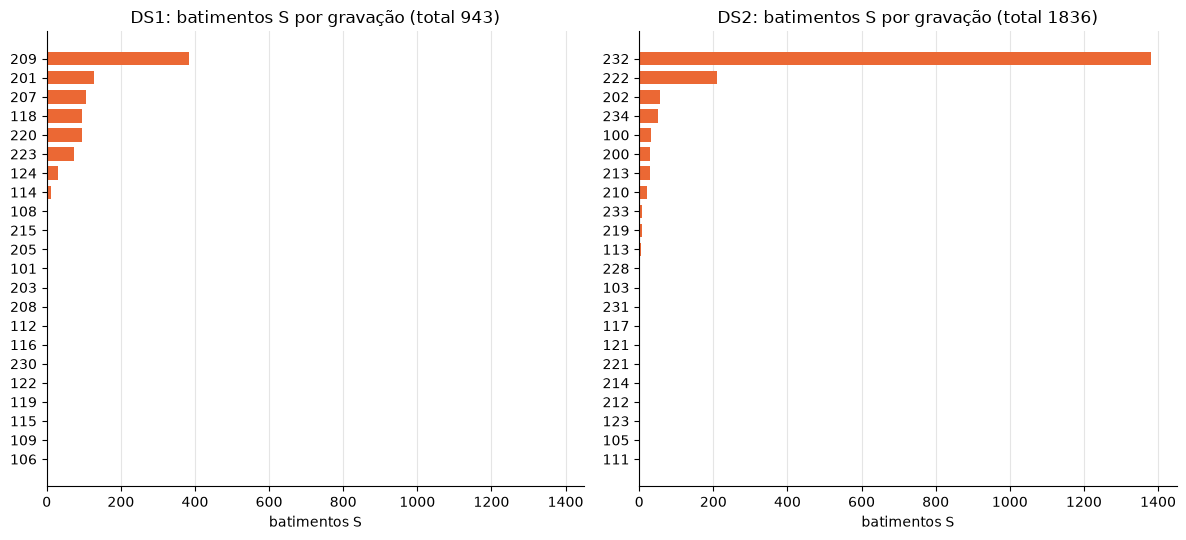

No DS2, a gravação 232 tem 1381 de 1836 batimentos S (75%).


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True)
for ax, (split, lista) in zip(eixos, [("DS1", DS1), ("DS2", DS2)]):
    n_s = df[(df["split"] == split) & (df["classe"] == "S")]["paciente"].value_counts()
    n_s = n_s.reindex(lista, fill_value=0).sort_values()
    ax.barh(n_s.index, n_s.values, color=CORES["S"], height=0.7)
    ax.set_title(f"{split}: batimentos S por gravação (total {n_s.sum()})")
    ax.set_xlabel("batimentos S")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

s_ds2 = df[(df["split"] == "DS2") & (df["classe"] == "S")]["paciente"].value_counts()
print(f"No DS2, a gravação {s_ds2.index[0]} tem {s_ds2.iloc[0]} de {s_ds2.sum()} batimentos S "
      f"({100 * s_ds2.iloc[0] / s_ds2.sum():.0f}%).")

### 4.3 Batimento médio por classe

**Como ler:** cada painel junta todos os batimentos de uma classe, alinhados pelo pico R (o 0 do eixo horizontal). A linha é a média, ou seja, o "batimento típico" da classe. A faixa clara mostra onde ficam os 50% de batimentos do meio (do 25º ao 75º percentil): faixa larga = batimentos muito diferentes entre si.

- **S tem formato quase igual ao N.** Só pela onda, separar S de N é difícil, e isso explica por que a S é a classe mais difícil.
- **V é a mais diferente e a mais variável** (faixa larga): o formato muda muito de paciente para paciente.
- **F tem formato próprio**, mas com poucos batimentos (802).

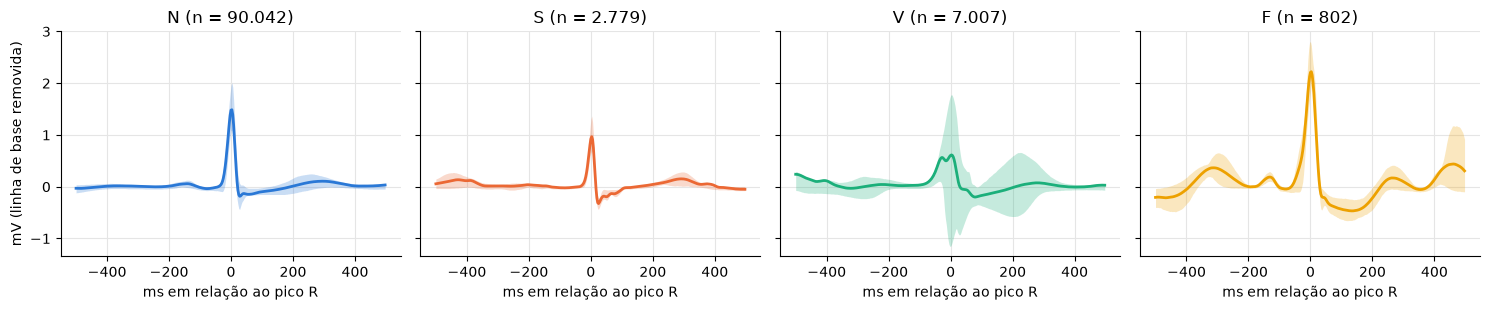

In [13]:
t_ms = np.arange(-ANTES, DEPOIS) / 360 * 1000  # tempo em ms, com o pico R em 0
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, classe in zip(eixos, CLASSES):
    janelas = X[df["classe"].values == classe]
    janelas = janelas - np.median(janelas, axis=1, keepdims=True)  # só para o gráfico: tira a linha de base
    p25, p75 = np.percentile(janelas, [25, 75], axis=0)
    ax.fill_between(t_ms, p25, p75, color=CORES[classe], alpha=0.25, lw=0)
    ax.plot(t_ms, janelas.mean(axis=0), color=CORES[classe], lw=2)
    ax.set_title(f"{classe} (n = {len(janelas):,})".replace(",", "."))
    ax.set_xlabel("ms em relação ao pico R")
eixos[0].set_ylabel("mV (linha de base removida)")
plt.tight_layout()
plt.show()

### 4.4 Intervalo RR por classe

**Como ler:** cada caixa resume o RR anterior (tempo desde o batimento anterior) de uma classe. O traço no meio é a mediana, a caixa contém os 50% de batimentos do meio e as hastes mostram a faixa típica (valores extremos omitidos). No gráfico da direita, 1,0 = o ritmo normal daquele paciente e 0,7 = chegou 30% antes do esperado.

- **RR cru (esquerda):** S chega um pouco antes que N, mas as caixas se sobrepõem bastante, porque cada paciente tem sua frequência cardíaca.
- **RR relativo ao ritmo da própria gravação (direita):** S fica claramente separado de N (mediana ~0,7 contra ~1,0), sem sobreposição das caixas.

Isso apoia a proposta do E5: dar ao modelo o RR **relativo ao ritmo do paciente**, já que é o ritmo, e não o formato, que distingue S de N. Aqui a média usa a gravação inteira, o que serve só para a EDA; no modelo, o certo é usar a média dos batimentos **anteriores**, como seria em tempo real.

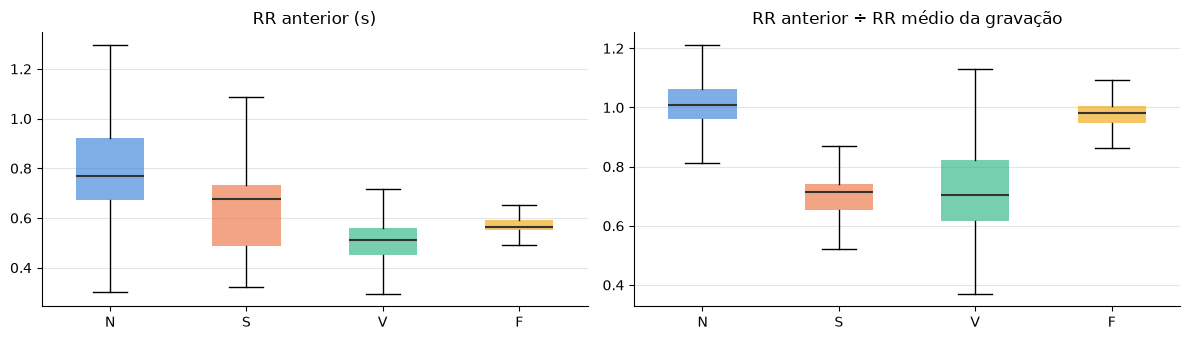

In [14]:
# Só para a EDA: RR anterior cru e dividido pelo RR médio da própria gravação
rr_relativo = df["rr_anterior"] / df.groupby("paciente")["rr_anterior"].transform("mean")

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, valores, titulo in [(eixos[0], df["rr_anterior"], "RR anterior (s)"),
                            (eixos[1], rr_relativo, "RR anterior ÷ RR médio da gravação")]:
    caixas = ax.boxplot([valores[df["classe"] == c] for c in CLASSES], tick_labels=CLASSES,
                        showfliers=False, patch_artist=True, widths=0.5,
                        medianprops={"color": "#333333", "lw": 1.5})
    for caixa, classe in zip(caixas["boxes"], CLASSES):
        caixa.set(facecolor=CORES[classe], alpha=0.6, lw=0)
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 5. Divisão dos dados

O ponto central do projeto. Fazemos dois splits **dos mesmos batimentos**, para que a única diferença seja misturar ou não os pacientes:

- **Aleatório por batimento:** sorteia 50% dos batimentos para o teste (estratificado por classe, para manter as proporções). Batimentos do mesmo paciente caem no treino e no teste. É o que gera os resultados "bonitos".
- **Por paciente (DS1 → DS2):** o teste só tem pacientes que o modelo nunca viu. É o cenário real de um hospital. Os tamanhos são parecidos com os do aleatório (~50/50).

Nos dois casos, a **validação** (usada para decidir quando parar o treino) segue a mesma lógica do split: sorteada por batimento no aleatório e **separada por paciente** no por paciente.

**Escolhas (provisórias, a confirmar com o Tom):**
- **Entrada do modelo: 0,25 s antes e 0,45 s depois do pico R** (252 amostras), recortada da janela de 1 s. Cobre a onda P e a onda T sem pegar muito dos batimentos vizinhos.
- **Normalização por batimento:** cada janela tem a média subtraída e é dividida pelo próprio desvio. O modelo vê o formato da onda, não a amplitude (que depende do eletrodo e da pessoa). Como não usa estatísticas de outros batimentos, não tem como vazar informação do teste.
- **Validação por paciente: gravações 118, 119, 124, 205 e 220** (5 dos 22 pacientes do DS1). Escolhidas olhando **só o DS1**, para que a validação tenha N, S, V e F e o treino não perca a 208 (que tem 90% dos F do DS1) nem a 209 (41% dos S).
- A classe Q (15 batimentos) sai.

In [15]:
INICIO, FIM = ANTES - 90, ANTES + 162  # 0,25 s antes e 0,45 s depois do pico R
CLASSE_PARA_INDICE = {c: k for k, c in enumerate(CLASSES)}

manter = (df["classe"] != "Q").values
dados = df[manter].reset_index(drop=True)
entrada = X[manter, INICIO:FIM]
entrada = (entrada - entrada.mean(axis=1, keepdims=True)) / entrada.std(axis=1, keepdims=True)
rotulo = dados["classe"].map(CLASSE_PARA_INDICE).values

print("Entrada do modelo:", entrada.shape)

Entrada do modelo: (100630, 252)


In [16]:
from sklearn.model_selection import train_test_split

# Split por paciente: treino e validação vêm do DS1, teste é o DS2
VALIDACAO = ["118", "119", "124", "205", "220"]
paciente = dados["paciente"]
por_paciente = {
    "treino": np.where(paciente.isin(DS1) & ~paciente.isin(VALIDACAO))[0],
    "validacao": np.where(paciente.isin(VALIDACAO))[0],
    "teste": np.where(paciente.isin(DS2))[0],
}

# Split aleatório: os mesmos batimentos, sorteados 50/50; validação = 20% do treino, também sorteada
indices = np.arange(len(dados))
treino_val, teste = train_test_split(indices, test_size=0.5, stratify=rotulo, random_state=SEED)
treino, validacao = train_test_split(treino_val, test_size=0.2, stratify=rotulo[treino_val], random_state=SEED)
aleatorio = {"treino": treino, "validacao": validacao, "teste": teste}

In [17]:
resumo = []
for nome, partes in [("aleatório", aleatorio), ("por paciente", por_paciente)]:
    for parte, idx in partes.items():
        contagem = pd.Series(rotulo[idx]).value_counts().reindex(range(4), fill_value=0)
        resumo.append({"split": nome, "parte": parte, "pacientes": paciente[idx].nunique(),
                       **dict(zip(CLASSES, contagem.values))})
    comuns = set(paciente[partes["treino"]]) & set(paciente[partes["teste"]])
    print(f"{nome}: {len(comuns)} pacientes aparecem no treino E no teste")
pd.DataFrame(resumo)

aleatório: 44 pacientes aparecem no treino E no teste
por paciente: 0 pacientes aparecem no treino E no teste


,split,parte,pacientes,N,S,V,F
0,aleatório,treino,44,36017,1112,2802,321
1,aleatório,validacao,44,9004,278,701,80
2,aleatório,teste,44,45021,1389,3504,401
3,por paciente,treino,17,36064,719,3210,398
4,por paciente,validacao,5,9760,224,578,16
5,por paciente,teste,22,44218,1836,3219,388


## 6. Experimentos

Mudamos uma coisa por vez. As métricas principais são recall, precisão e F1 **por classe** e o F1 macro (média do F1 das 4 classes, sem peso pelo tamanho). Acurácia aparece só como referência, porque ~90% dos batimentos são N.

- **Recall** de uma classe: dos batimentos que *são* dessa classe, quantos o modelo achou.
- **Precisão**: dos batimentos que o modelo *disse* ser dessa classe, quantos eram mesmo.
- **F1**: combina os dois num número só.

| Exp. | O que muda | Split |
|---|---|---|
| E0 | Sempre chuta "N" (não aprende nada) | por paciente |
| E1 | MLP base | aleatório |
| E2 | A mesma MLP do E1 | por paciente |
| E3 | E2 + peso por classe | por paciente |
| E4 | E2 + oversampling (só no treino) | por paciente |
| E5 | E2 + intervalo RR | por paciente |

A tabela com os números é **gerada pelo código** no fim desta seção, a partir do que foi rodado.

### Ferramentas comuns

**MLP base** (igual em todos os experimentos; só muda o que a tabela acima diz):
252 entradas → Dense 128 (ReLU) → Dropout 0,3 → Dense 64 (ReLU) → Dropout 0,3 → Dense 4 (softmax).
Otimizador Adam (taxa 0,001), batch 256, até 50 épocas. O treino para quando a loss de validação passa 5 épocas sem melhorar, e voltamos aos pesos da melhor época (*early stopping*). O Dropout desliga neurônios aleatórios durante o treino para o modelo não decorar os dados (regularização, Aula 7).

`avaliar` calcula as métricas, guarda na tabela de resultados e desenha a **matriz de confusão**: cada linha é a classe verdadeira, cada coluna é o que o modelo previu, e a cor mostra a % da linha (a diagonal é o recall).

In [18]:
import tensorflow as tf
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

resultados = []  # uma linha por experimento; vira a tabela no fim da seção


def avaliar(nome, y_true, y_pred, epocas=None):
    """Métricas por classe + matriz de confusão. Rodar de novo o mesmo experimento substitui a linha."""
    precisao, recall, f1, suporte = precision_recall_fscore_support(y_true, y_pred, labels=range(4), zero_division=0)
    linha = {"exp": nome, "épocas": epocas, "acurácia": (y_true == y_pred).mean(), "F1 macro": f1.mean()}
    for k, c in enumerate(CLASSES):
        linha[f"recall {c}"], linha[f"precisão {c}"], linha[f"F1 {c}"] = recall[k], precisao[k], f1[k]
    resultados[:] = [r for r in resultados if r["exp"] != nome] + [linha]

    matriz = confusion_matrix(y_true, y_pred, labels=range(4))
    porcentagem = matriz / matriz.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(porcentagem, cmap="Blues", vmin=0, vmax=1)
    for a in range(4):
        for b in range(4):
            ax.text(b, a, f"{porcentagem[a, b]:.0%}\n({matriz[a, b]})", ha="center", va="center", fontsize=8,
                    color="white" if porcentagem[a, b] > 0.6 else "#222222")
    ax.set_xticks(range(4), CLASSES)
    ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel("previsto")
    ax.set_ylabel("verdadeiro")
    ax.set_title(nome, fontsize=10)
    ax.grid(False)
    plt.show()

    return pd.DataFrame({"precisão": precisao, "recall": recall, "F1": f1, "batimentos": suporte},
                        index=CLASSES).round(3)


def criar_mlp():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(entrada.shape[1],)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(len(CLASSES), activation="softmax"),
    ])


def treinar_mlp(partes, titulo):
    """Treina a MLP base com early stopping na validação e devolve (modelo, épocas, previsões no teste)."""
    tf.keras.utils.set_random_seed(SEED)
    modelo = criar_mlp()
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    historico = modelo.fit(entrada[partes["treino"]], rotulo[partes["treino"]],
                           validation_data=(entrada[partes["validacao"]], rotulo[partes["validacao"]]),
                           epochs=50, batch_size=256, callbacks=[parada], verbose=0)

    perdas = historico.history
    melhor = int(np.argmin(perdas["val_loss"])) + 1
    plt.figure(figsize=(6, 3))
    epocas = range(1, len(perdas["loss"]) + 1)
    plt.plot(epocas, perdas["loss"], color="#555555", lw=2, label="treino")
    plt.plot(epocas, perdas["val_loss"], color="#2a78d6", lw=2, label="validação")
    plt.axvline(melhor, color="#999999", ls="--", lw=1)
    plt.text(melhor, max(perdas["val_loss"]), f" melhor época ({melhor})", color="#555555", va="top", fontsize=9)
    plt.xlabel("época")
    plt.ylabel("loss")
    plt.title(f"Curvas de loss: {titulo}", fontsize=10)
    plt.legend(frameon=False)
    plt.show()

    previsto = modelo.predict(entrada[partes["teste"]], verbose=0).argmax(axis=1)
    return modelo, melhor, previsto

### E0. Baseline "sempre N"

Mostra que acurácia alta não quer dizer nada aqui: chutar sempre "N" acerta a maioria e erra todas as arritmias.

**Resultado:** acurácia de 89% sem acertar nenhuma arritmia (recall 0 em S, V e F) e F1 macro de 0,24. É o piso: um modelo útil precisa superar isso no F1 macro, não na acurácia.

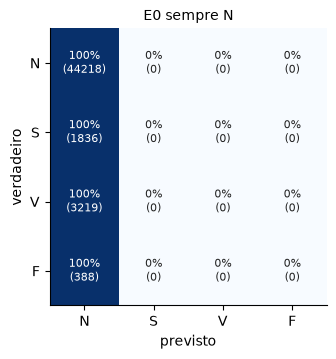

,precisão,recall,F1,batimentos
N,0.89,1.0,0.942,44218
S,0.00,0.0,0.000,1836
V,0.00,0.0,0.000,3219
F,0.00,0.0,0.000,388


In [19]:
y_teste = rotulo[por_paciente["teste"]]
avaliar("E0 sempre N", y_teste, np.zeros_like(y_teste))

### E1. MLP com split aleatório

Reproduz o resultado "bonito" da literatura: a MLP base treinada e testada com o split aleatório.

**Resultado:** acurácia de 98,5% e F1 macro de 0,89, o tipo de número que aparece nos artigos. Recall: N 99,7%, S 75%, V 96%, F 68%.

Nas curvas de loss, treino e validação caem juntas até a época 31. Como a validação tem os mesmos pacientes do treino, o que o modelo aprende sobre cada pessoa também "funciona" na validação.

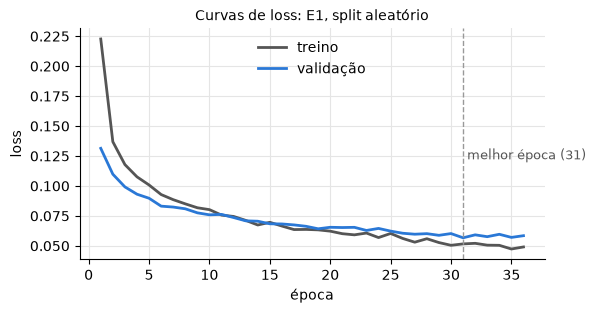

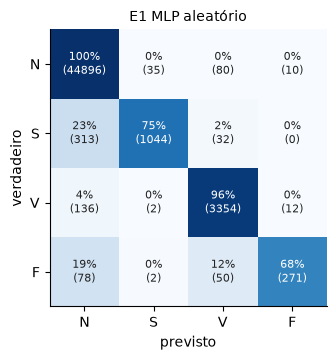

,precisão,recall,F1,batimentos
N,0.988,0.997,0.993,45021
S,0.964,0.752,0.845,1389
V,0.954,0.957,0.956,3504
F,0.925,0.676,0.781,401


In [20]:
modelo_e1, epocas_e1, previsto_e1 = treinar_mlp(aleatorio, "E1, split aleatório")
avaliar("E1 MLP aleatório", rotulo[aleatorio["teste"]], previsto_e1, epocas_e1)

### E2. MLP com split por paciente

A mesma MLP do E1, agora com o split por paciente. A diferença entre E1 e E2 é o resultado principal do projeto.

**Resultado:** com pacientes novos, o desempenho desaba. O F1 macro cai de 0,89 para **0,39**, o recall de S cai de 75% para **5%** e o de F, de 68% para **0%**. A acurácia (86%) fica abaixo até do "sempre N" (89%).

- **Curvas de loss:** a loss de validação é mínima já na **época 1** e só sobe depois, enquanto a de treino continua caindo. O modelo passa a decorar os pacientes do treino em vez de aprender a arritmia. O early stopping guarda os pesos da época 1, então treinar mais só pioraria o resultado em pacientes novos.
- **Matriz de confusão:** 56% dos S viram N e 39% viram V; 92% dos F viram N; e 8% dos N (3.680 batimentos) viram V, o que derruba a precisão de V para 38%.

Ressalva: é o resultado de **uma seed só**. O motivo dos erros de S (por exemplo, quanto vem da gravação 232) fica para a seção 7.

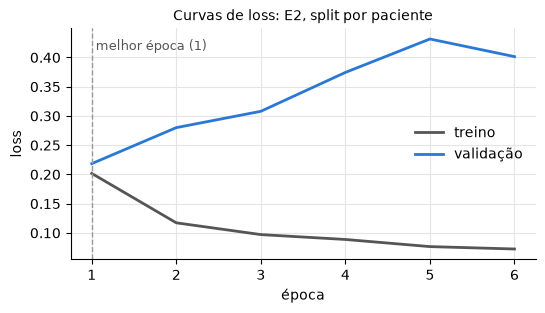

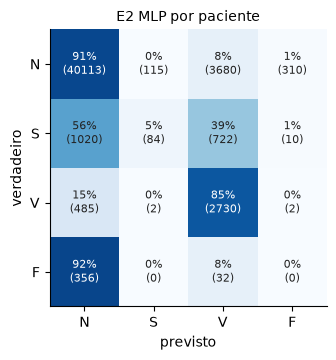

,precisão,recall,F1,batimentos
N,0.956,0.907,0.931,44218
S,0.418,0.046,0.082,1836
V,0.381,0.848,0.526,3219
F,0.000,0.000,0.000,388


In [21]:
modelo_e2, epocas_e2, previsto_e2 = treinar_mlp(por_paciente, "E2, split por paciente")
avaliar("E2 MLP por paciente", rotulo[por_paciente["teste"]], previsto_e2, epocas_e2)

### E3. Peso por classe

Errar um batimento raro (S, V, F) passa a custar mais na loss do que errar um N. **A fazer.**

### E4. Oversampling

Repete batimentos das classes raras, **só no treino e depois do split**. **A fazer.**

### E5. Intervalo RR como entrada

Um batimento S costuma chegar antes do esperado, e o formato da onda sozinho não mostra isso. Adicionamos o tempo até o batimento anterior e até o próximo. **A fazer.**

### Tabela de resultados

Gerada a partir dos experimentos rodados acima. O gráfico compara o recall de cada classe entre o split aleatório (E1) e o por paciente (E2).

**Resposta à pergunta de pesquisa (primeira parte):** o mesmo modelo, com os mesmos batimentos, vai de F1 macro 0,89 para 0,39 só por mudar a forma de dividir os dados. A maior perda está nas classes raras e clinicamente importantes (S e F).

In [22]:
colunas = ["épocas", "acurácia", "F1 macro"] + [f"recall {c}" for c in CLASSES] + [f"precisão {c}" for c in CLASSES]
pd.DataFrame(resultados).set_index("exp")[colunas].round(3)

,épocas,acurácia,F1 macro,recall N,recall S,recall V,recall F,precisão N,precisão S,precisão V,precisão F
exp,,,,,,,,,,,
E0 sempre N,NaN,0.890,0.236,1.000,0.000,0.000,0.000,0.890,0.000,0.000,0.000
E1 MLP aleatório,31.0,0.985,0.893,0.997,0.752,0.957,0.676,0.988,0.964,0.954,0.925
E2 MLP por paciente,1.0,0.864,0.385,0.907,0.046,0.848,0.000,0.956,0.418,0.381,0.000


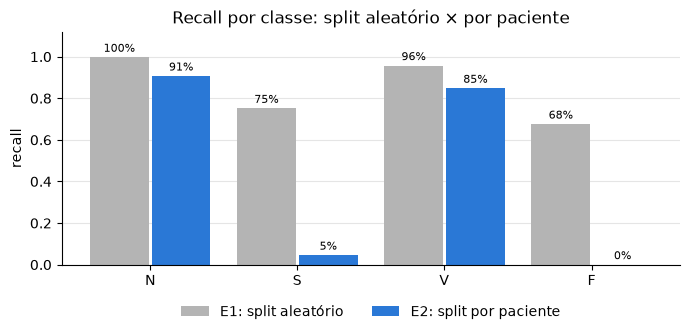

In [23]:
tabela = pd.DataFrame(resultados).set_index("exp")
e1 = tabela.loc["E1 MLP aleatório", [f"recall {c}" for c in CLASSES]].values
e2 = tabela.loc["E2 MLP por paciente", [f"recall {c}" for c in CLASSES]].values

x = np.arange(len(CLASSES))
fig, ax = plt.subplots(figsize=(7, 3.5))
barras1 = ax.bar(x - 0.21, e1, width=0.4, color="#b4b4b4", label="E1: split aleatório")
barras2 = ax.bar(x + 0.21, e2, width=0.4, color="#2a78d6", label="E2: split por paciente")
for barras in (barras1, barras2):
    ax.bar_label(barras, labels=[f"{v:.0%}" for v in barras.datavalues], fontsize=8, padding=2)
ax.set_xticks(x, CLASSES)
ax.set_ylim(0, 1.12)
ax.set_ylabel("recall")
ax.set_title("Recall por classe: split aleatório × por paciente")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

## 7. Análise de erros (classe S)

Onde a classe S falha: matriz de confusão, desempenho por paciente do DS2 e exemplos de batimentos S classificados como N. **A fazer.**

## 8. Conclusões e limitações

**A fazer**, depois dos experimentos.

## Bônus

Só se o núcleo estiver pronto. Candidatos: Conv1D, Grad-CAM/saliency (não visto nas aulas), focal loss, teste no INCART.